# Assignment 1: Five-model comparison on Fashion-MNIST

This notebook trains and evaluates the five mandatory models under one shared split: Linear, MLP, CNN, GRU and Transformer.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "assignment1").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "assignment1"))
sys.path.insert(0, str(REPO_ROOT))

from training_loop import preprocess, set_seed
from utils.dataloader import get_dataloaders, load_split
from models.linear import LinearClassifier
from models.mlp import MLP
from models.cnn import CNNClassifier
from models.rnn import GRUClassifier
from models.transformer import TransformerClassifier


## 1. Dataset, split and DataLoaders

In [2]:
set_seed()

(X_train, y_train), (X_validate, y_validate), (X_test, y_test) = load_split(dataset_name="fashion_mnist")
(X_train, X_validate, X_test), (mean, std) = preprocess(X_train, X_validate, X_test)
train_loader, validation_loader, test_loader = get_dataloaders(
    X_train, y_train, X_validate, y_validate, X_test, y_test
)

print("Train/Validation/Test:", len(y_train), len(y_validate), len(y_test))
print("Input shape and dtype:", tuple(X_train.shape), X_train.dtype)


Train/Validation/Test: 48000 12000 10000
Input shape and dtype: (48000, 1, 28, 28) torch.float32


## 2. Training and evaluation utilities

In [3]:
import copy
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

SEED = 42
EPOCHS = 10
LR = 1e-3
BATCH_SIZE = 64
MONITOR = "validation_macro_f1"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

CHECKPOINT_DIR = REPO_ROOT / "assignment1" / "checkpoints"
RESULTS_DIR = REPO_ROOT / "assignment1" / "results"
for path in [
    CHECKPOINT_DIR,
    RESULTS_DIR,
    RESULTS_DIR / "curves",
    RESULTS_DIR / "confusion",
    RESULTS_DIR / "examples",
    RESULTS_DIR / "history",
]:
    path.mkdir(parents=True, exist_ok=True)


def is_improvement(current, best, monitor):
    return current < best if monitor == "validation_loss" else current > best


@torch.no_grad()
def evaluate_model(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    predictions, targets = [], []
    for X, y in dataloader:
        X = X.to(device)
        y = y.to(device)
        logits = model(X)
        total_loss += criterion(logits, y).item() * X.size(0)
        predictions.append(logits.argmax(dim=1).cpu())
        targets.append(y.cpu())
    predictions = torch.cat(predictions).numpy()
    targets = torch.cat(targets).numpy()
    loss = total_loss / len(targets)
    accuracy = float((predictions == targets).mean())
    macro_f1 = float(f1_score(targets, predictions, average="macro"))
    return loss, accuracy, macro_f1, predictions, targets


def fit(model, train_loader, validation_loader, checkpoint_path, device,
        epochs, lr, seed, monitor, clip_grad_norm=1.0):
    set_seed(seed)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "validation_loss": [],
        "validation_accuracy": [],
        "validation_macro_f1": [],
        "epoch_time": [],
    }
    best_value = float("inf") if monitor == "validation_loss" else -float("inf")
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):
        start = time.perf_counter()
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0

        for X, y in train_loader:
            X = X.to(device)
            y = y.to(device)
            logits = model(X)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            if clip_grad_norm is not None and clip_grad_norm > 0:
                nn.utils.clip_grad_norm_(model.parameters(), clip_grad_norm)
            optimizer.step()

            total_loss += loss.item() * X.size(0)
            correct += (logits.argmax(dim=1) == y).sum().item()
            total += y.size(0)

        train_loss = total_loss / total
        train_accuracy = correct / total
        validation_loss, validation_accuracy, validation_macro_f1, _, _ = evaluate_model(
            model, validation_loader, criterion, device
        )
        epoch_time = time.perf_counter() - start

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["validation_loss"].append(validation_loss)
        history["validation_accuracy"].append(validation_accuracy)
        history["validation_macro_f1"].append(validation_macro_f1)
        history["epoch_time"].append(epoch_time)

        current = {
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "validation_macro_f1": validation_macro_f1,
        }[monitor]

        if is_improvement(current, best_value, monitor):
            best_value = current
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())
            checkpoint_path = Path(checkpoint_path)
            checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
            torch.save(
                {
                    "model_state_dict": best_state,
                    "epoch": best_epoch,
                    "monitor": monitor,
                    "value": best_value,
                },
                checkpoint_path,
            )

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"Train loss: {train_loss:.4f} Train accuracy: {train_accuracy:.4f} "
            f"Validation loss: {validation_loss:.4f} "
            f"Validation accuracy: {validation_accuracy:.4f} "
            f"Validation macro-F1: {validation_macro_f1:.4f} "
            f"Time: {epoch_time:.1f}s"
        )

    model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    history["best_value"] = best_value
    history["monitor"] = monitor
    return history


@torch.no_grad()
def measure_inference_time(model, dataloader, device, warmup_batches=2):
    model.eval()
    iterator = iter(dataloader)
    for _ in range(warmup_batches):
        try:
            X, _ = next(iterator)
        except StopIteration:
            break
        model(X.to(device))

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()
    total = 0
    for X, _ in dataloader:
        model(X.to(device))
        total += X.size(0)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    return elapsed, 1000.0 * elapsed / total if total else float("nan")


def plot_curves(history, path, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].plot(epochs, history["train_loss"], marker="o", markersize=3, label="train")
    axes[0].plot(epochs, history["validation_loss"], marker="o", markersize=3, label="validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy")
    axes[0].legend()

    axes[1].plot(epochs, history["train_accuracy"], marker="o", markersize=3, label="train")
    axes[1].plot(epochs, history["validation_accuracy"], marker="o", markersize=3, label="validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].legend()

    axes[2].plot(epochs, history["validation_macro_f1"], marker="o", markersize=3, label="validation")
    axes[2].set_title("Macro-F1")
    axes[2].set_xlabel("epoch")
    axes[2].set_ylabel("macro-F1")
    axes[2].legend()

    best_epoch = history.get("best_epoch", 0)
    if best_epoch:
        for ax in axes:
            ax.axvline(best_epoch, color="0.5", linestyle="--", linewidth=1)

    for ax in axes:
        ax.grid(alpha=0.3)

    fig.suptitle(f"{title} — best epoch {best_epoch} by {history.get('monitor')}")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def plot_confusion(cm, class_names, path, title):
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)

    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        ylabel="True label",
        xlabel="Predicted label",
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    threshold = cm.max() / 2.0 if cm.size else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, format(int(cm[i, j]), "d"),
                ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > threshold else "black",
            )

    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def plot_examples(X_test, targets, predictions, class_names, path, title, mean, std):
    correct = np.where(predictions == targets)[0]
    incorrect = np.where(predictions != targets)[0]
    chosen = list(correct[:5]) + list(incorrect[:5])

    fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
    for ax in axes.ravel():
        ax.axis("off")

    for position, index in enumerate(chosen[:10]):
        ax = axes.ravel()[position]
        image = X_test[index].cpu().numpy()
        if image.shape[0] == 1:
            image = image[0]
        else:
            image = np.transpose(image, (1, 2, 0))
        image = np.clip(image * std + mean, 0.0, 1.0)

        if image.ndim == 2:
            ax.imshow(image, cmap="gray")
        else:
            ax.imshow(image)

        is_correct = predictions[index] == targets[index]
        ax.set_title(
            f"T: {class_names[targets[index]]}\nP: {class_names[predictions[index]]}",
            color="green" if is_correct else "red",
            fontsize=8,
        )

    fig.suptitle(f"{title} — top row: correct, bottom row: incorrect")
    fig.tight_layout()
    fig.subplots_adjust(hspace=0.35)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


Device: cuda


## 3. Train all five models

In [4]:
model_builders = {
    "Linear": lambda: LinearClassifier(input_shape=(1, 28, 28)),
    "MLP": lambda: MLP(input_dim=784),
    "CNN": lambda: CNNClassifier(input_shape=(1, 28, 28)),
    "GRU": lambda: GRUClassifier(input_shape=(1, 28, 28)),
    "Transformer": lambda: TransformerClassifier(input_shape=(1, 28, 28)),
}

criterion = nn.CrossEntropyLoss()
rows = []
histories = {}
per_class = {}
confusion_matrices = {}

for display_name, build in model_builders.items():
    print(f"\n{'=' * 70}\nTraining {display_name}\n{'=' * 70}")

    set_seed(SEED)
    model = build().to(device)
    params = model.num_para()
    checkpoint_path = CHECKPOINT_DIR / f"{display_name.lower()}.pt"

    start = time.perf_counter()
    history = fit(
        model,
        train_loader,
        validation_loader,
        checkpoint_path,
        device,
        EPOCHS,
        LR,
        SEED,
        MONITOR,
        clip_grad_norm=1.0,
    )
    train_time = time.perf_counter() - start

    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])

    test_loss, test_accuracy, test_macro_f1, predictions, targets = evaluate_model(
        model, test_loader, criterion, device
    )
    inference_time, inference_ms = measure_inference_time(model, test_loader, device)

    precision, recall, f1, support = precision_recall_fscore_support(
        targets, predictions, labels=list(range(10)), average=None, zero_division=0
    )
    cm = confusion_matrix(targets, predictions, labels=list(range(10)))

    histories[display_name] = history
    per_class[display_name] = [
        {
            "class_id": index,
            "class_name": CLASS_NAMES[index],
            "precision": float(precision[index]),
            "recall": float(recall[index]),
            "f1": float(f1[index]),
            "support": int(support[index]),
        }
        for index in range(10)
    ]
    confusion_matrices[display_name] = cm.tolist()

    with open(RESULTS_DIR / "history" / f"{display_name.lower()}.json", "w") as handle:
        json.dump(history, handle, indent=2)
    plot_curves(history, RESULTS_DIR / "curves" / f"{display_name.lower()}.png", display_name)
    plot_confusion(
        cm, CLASS_NAMES,
        RESULTS_DIR / "confusion" / f"{display_name.lower()}.png",
        f"{display_name} confusion matrix (test)",
    )
    plot_examples(
        X_test, targets, predictions, CLASS_NAMES,
        RESULTS_DIR / "examples" / f"{display_name.lower()}.png",
        f"{display_name} predictions", float(mean), float(std),
    )

    best_index = max(0, history["best_epoch"] - 1)
    rows.append({
        "Model": display_name,
        "Params": int(params),
        "Best epoch": int(history["best_epoch"]),
        "Val loss": float(history["validation_loss"][best_index]),
        "Val accuracy": float(history["validation_accuracy"][best_index]),
        "Val macro-F1": float(history["validation_macro_f1"][best_index]),
        "Test loss": float(test_loss),
        "Test accuracy": float(test_accuracy),
        "Test macro-F1": float(test_macro_f1),
        "Train time (s)": float(train_time),
        "Inference time (s)": float(inference_time),
        "Inference (ms/sample)": float(inference_ms),
    })

    print(
        f"{display_name}: params={params:,} best_epoch={history['best_epoch']} "
        f"test_acc={test_accuracy:.4f} test_macro_f1={test_macro_f1:.4f} "
        f"train_time={train_time:.1f}s inference={inference_ms:.3f}ms/sample"
    )



Training Linear


Epoch 1/10 Train loss: 0.5420 Train accuracy: 0.8114 Validation loss: 0.4436 Validation accuracy: 0.8458 Validation macro-F1: 0.8429 Time: 1.3s


Epoch 2/10 Train loss: 0.4490 Train accuracy: 0.8444 Validation loss: 0.4285 Validation accuracy: 0.8501 Validation macro-F1: 0.8495 Time: 0.9s


Epoch 3/10 Train loss: 0.4336 Train accuracy: 0.8499 Validation loss: 0.4302 Validation accuracy: 0.8524 Validation macro-F1: 0.8484 Time: 0.9s


Epoch 4/10 Train loss: 0.4230 Train accuracy: 0.8517 Validation loss: 0.4224 Validation accuracy: 0.8510 Validation macro-F1: 0.8530 Time: 0.9s


...

Epoch 7/10 Train loss: 0.2943 Train accuracy: 0.8912 Validation loss: 0.3296 Validation accuracy: 0.8836 Validation macro-F1: 0.8836 Time: 3.5s


Epoch 8/10 Train loss: 0.2830 Train accuracy: 0.8947 Validation loss: 0.2952 Validation accuracy: 0.8960 Validation macro-F1: 0.8959 Time: 3.4s


Epoch 9/10 Train loss: 0.2736 Train accuracy: 0.8980 Validation loss: 0.3145 Validation accuracy: 0.8852 Validation macro-F1: 0.8843 Time: 3.4s


Epoch 10/10 Train loss: 0.2648 Train accuracy: 0.9020 Validation loss: 0.3098 Validation accuracy: 0.8906 Validation macro-F1: 0.8901 Time: 3.4s


Transformer: params=69,450 best_epoch=8 test_acc=0.8871 test_macro_f1=0.8869 train_time=34.2s inference=0.013ms/sample


## 4. Results

In [5]:
results_df = pd.DataFrame(rows)
results_df.to_csv(RESULTS_DIR / "results.csv", index=False)

config = {
    "dataset": "fashion_mnist",
    "train_size": int(len(y_train)),
    "validation_size": int(len(y_validate)),
    "test_size": int(len(y_test)),
    "input_shape": [1, 28, 28],
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "lr": LR,
    "monitor": MONITOR,
    "clip_grad_norm": 1.0,
    "augmentation": "none",
    "device": str(device),
    "torch_version": torch.__version__,
    "cuda_version": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "normalization_mean": float(mean),
    "normalization_std": float(std),
}
with open(RESULTS_DIR / "results.json", "w") as handle:
    json.dump(
        {
            "config": config,
            "results": rows,
            "per_class": per_class,
            "confusion_matrix": confusion_matrices,
        },
        handle,
        indent=2,
    )
with open(RESULTS_DIR / "config.json", "w") as handle:
    json.dump(config, handle, indent=2)

results_df


,Model,Params,Best epoch,Val loss,Val accuracy,Val macro-F1,Test loss,Test accuracy,Test macro-F1,Train time (s),Inference time (s),Inference (ms/sample)
0,Linear,7850,8,0.407074,0.858917,0.859374,0.450646,0.8410,0.841540,9.337005,0.053424,0.005342
1,MLP,235146,8,0.306286,0.895500,0.895690,0.350751,0.8789,0.878940,11.999270,0.066753,0.006675
2,CNN,455946,10,0.293305,0.928500,0.928142,0.342345,0.9190,0.918551,20.861060,0.106606,0.010661
3,GRU,61962,8,0.270598,0.901500,0.901021,0.291999,0.8893,0.888519,14.526206,0.073572,0.007357
4,Transformer,69450,8,0.295223,0.896000,0.895942,0.316064,0.8871,0.886915,34.178303,0.128738,0.012874


## 5. Curves, confusion matrices, and prediction examples

### CNN


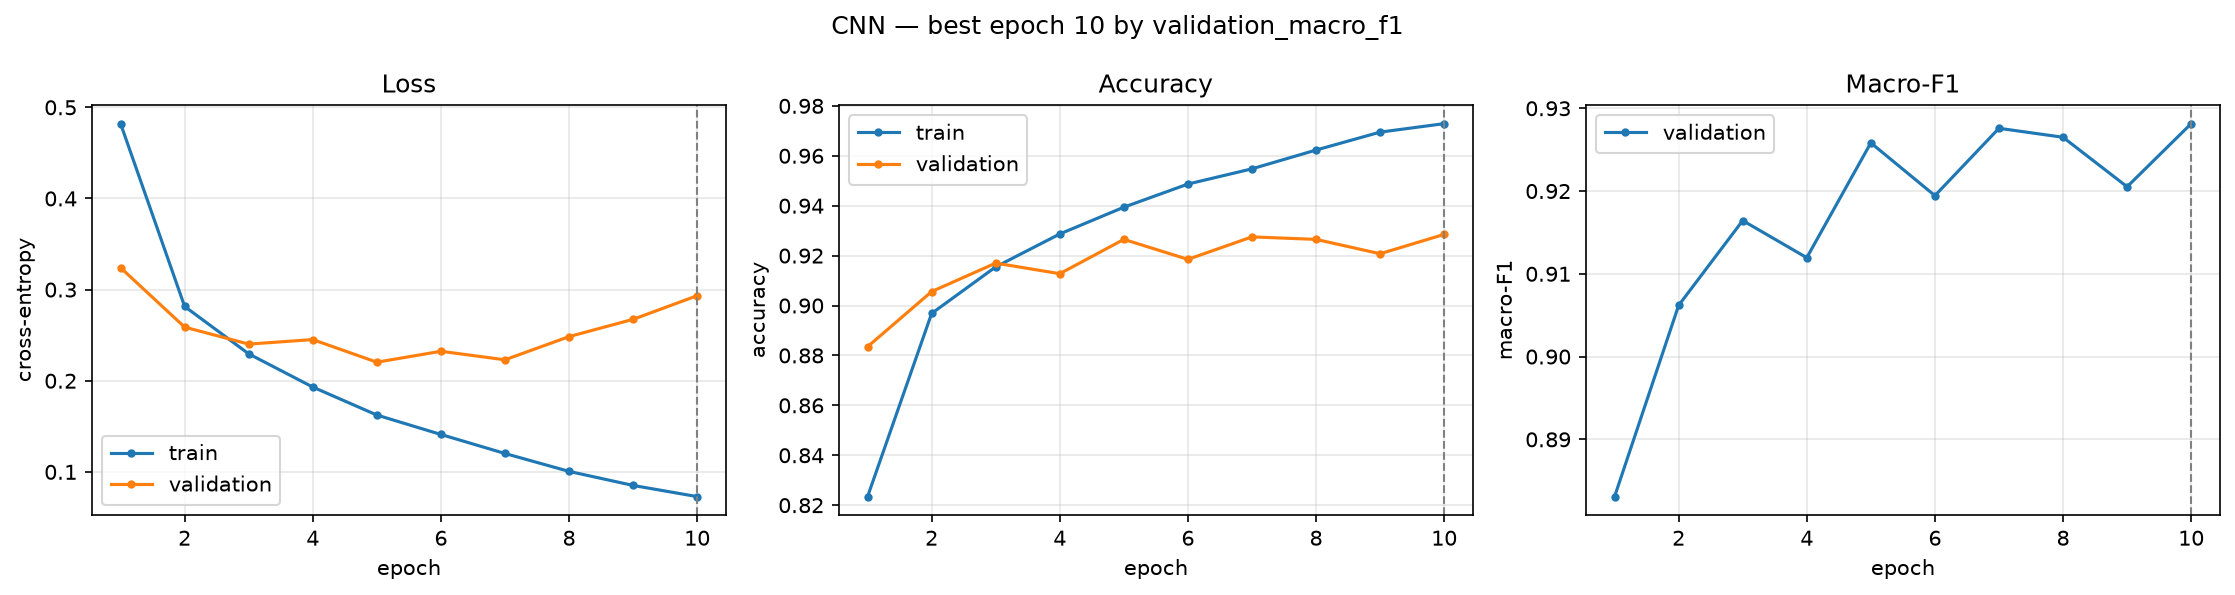

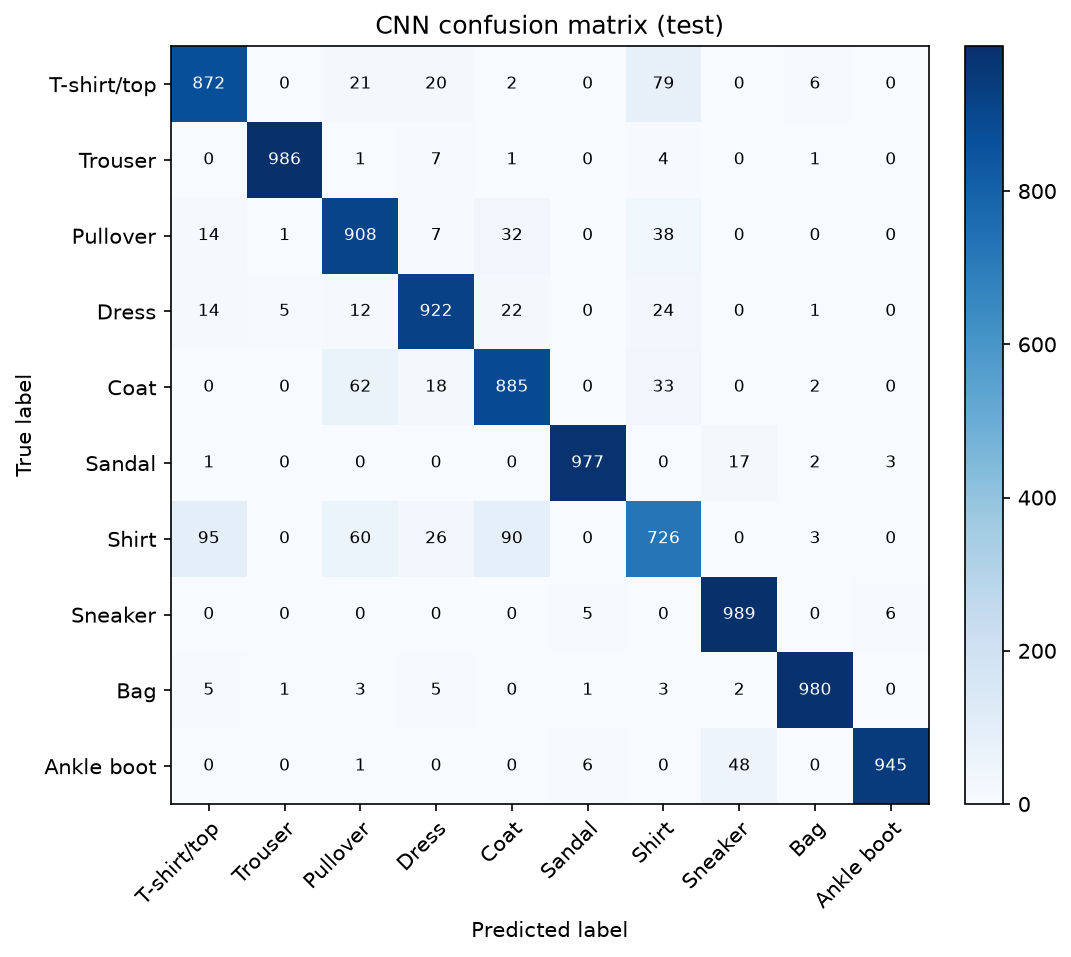

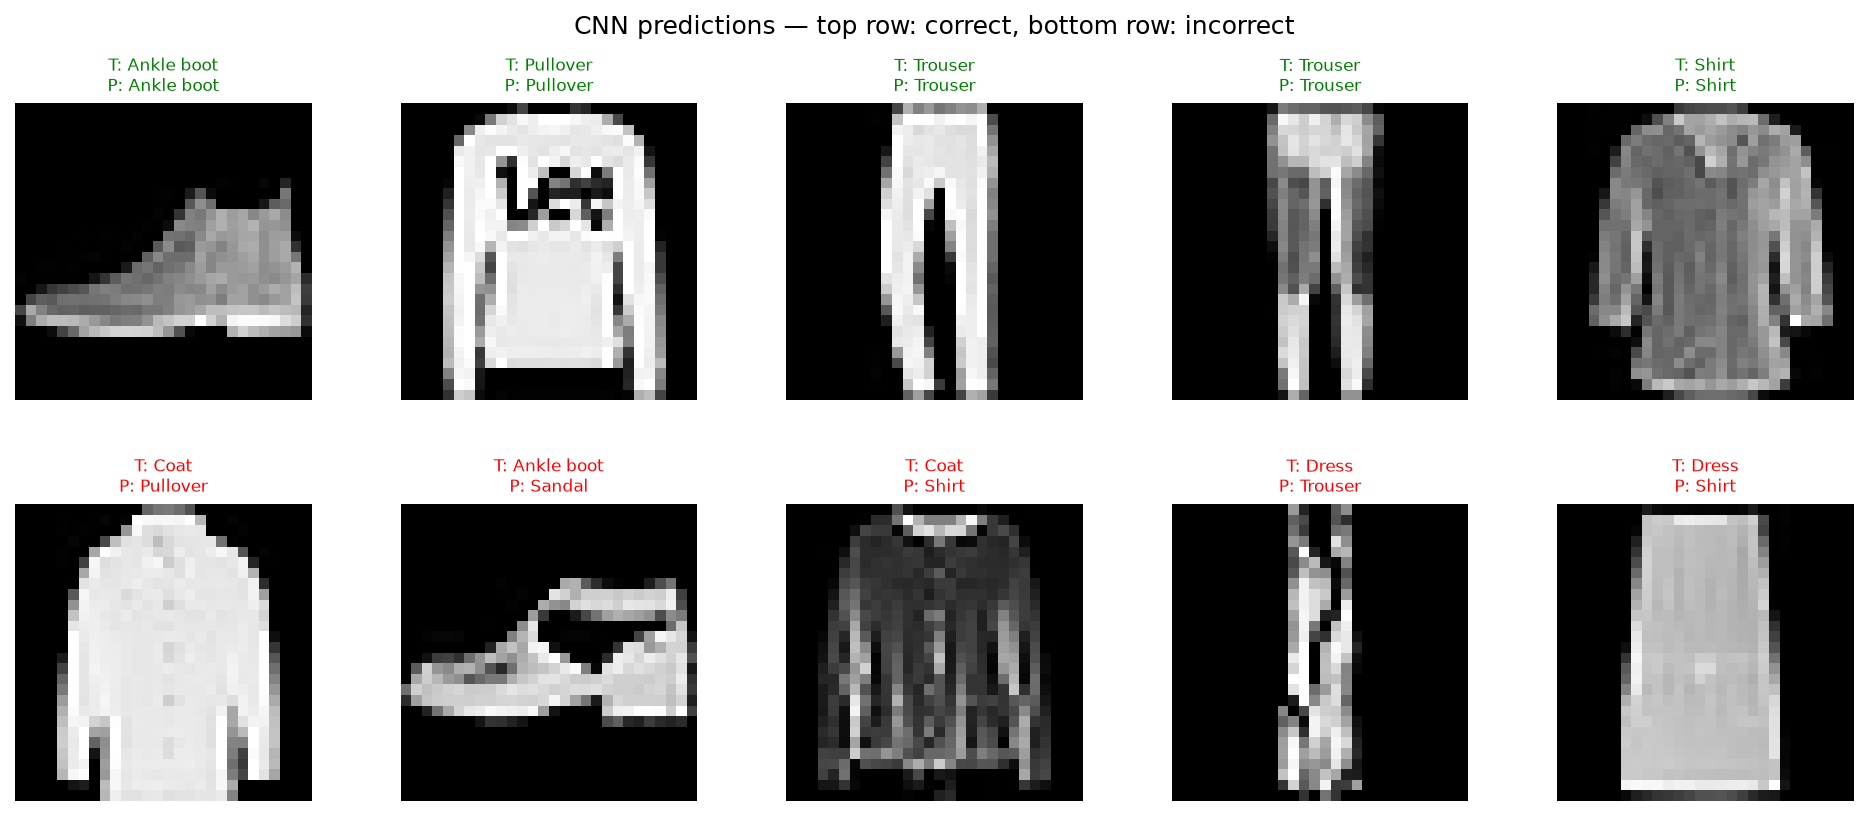

### Transformer


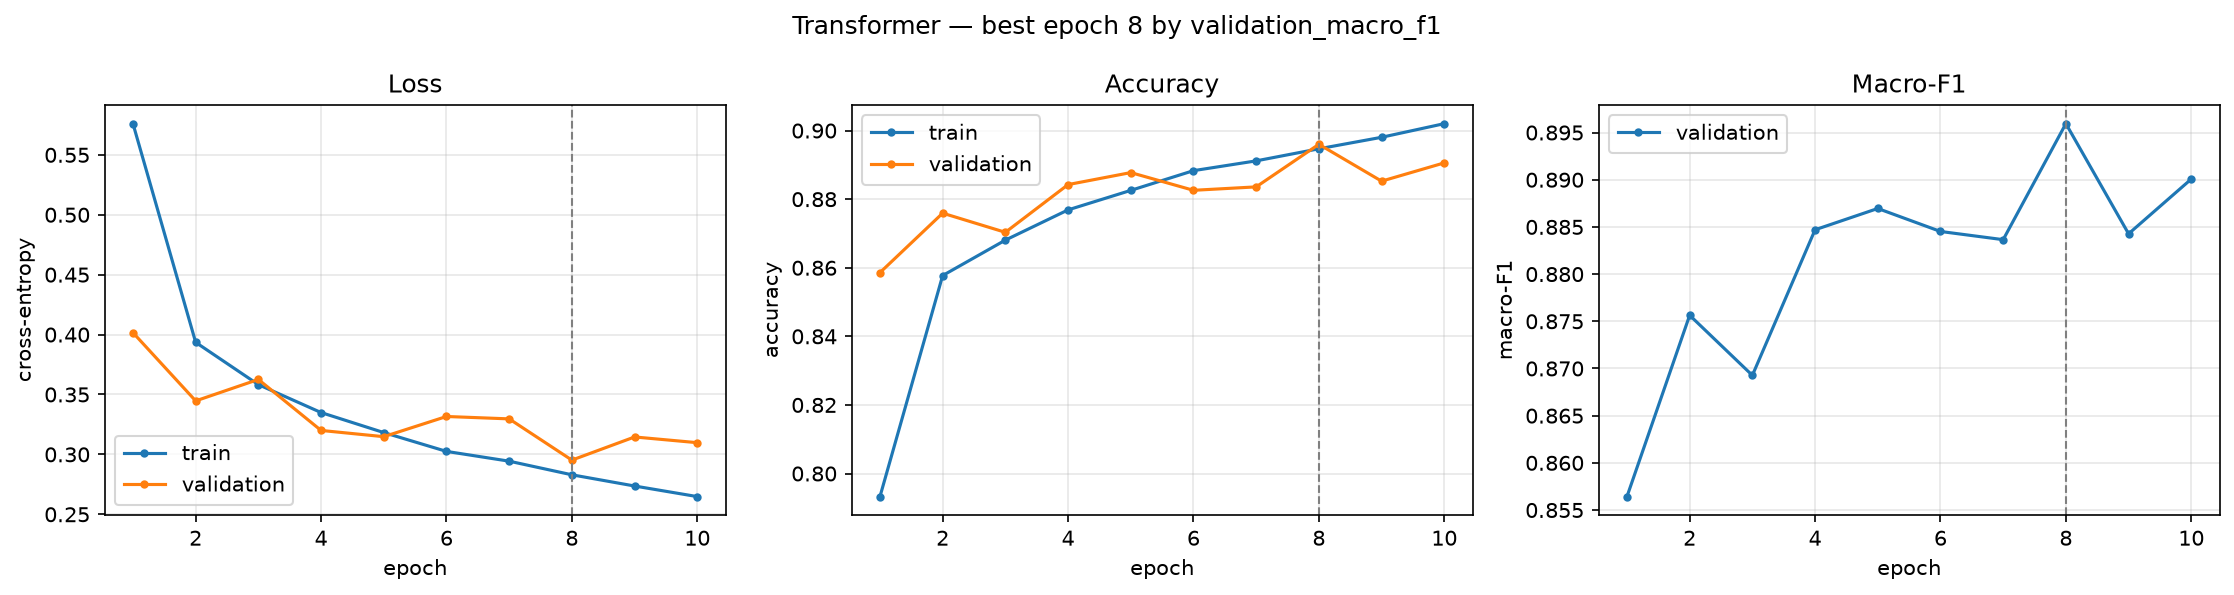

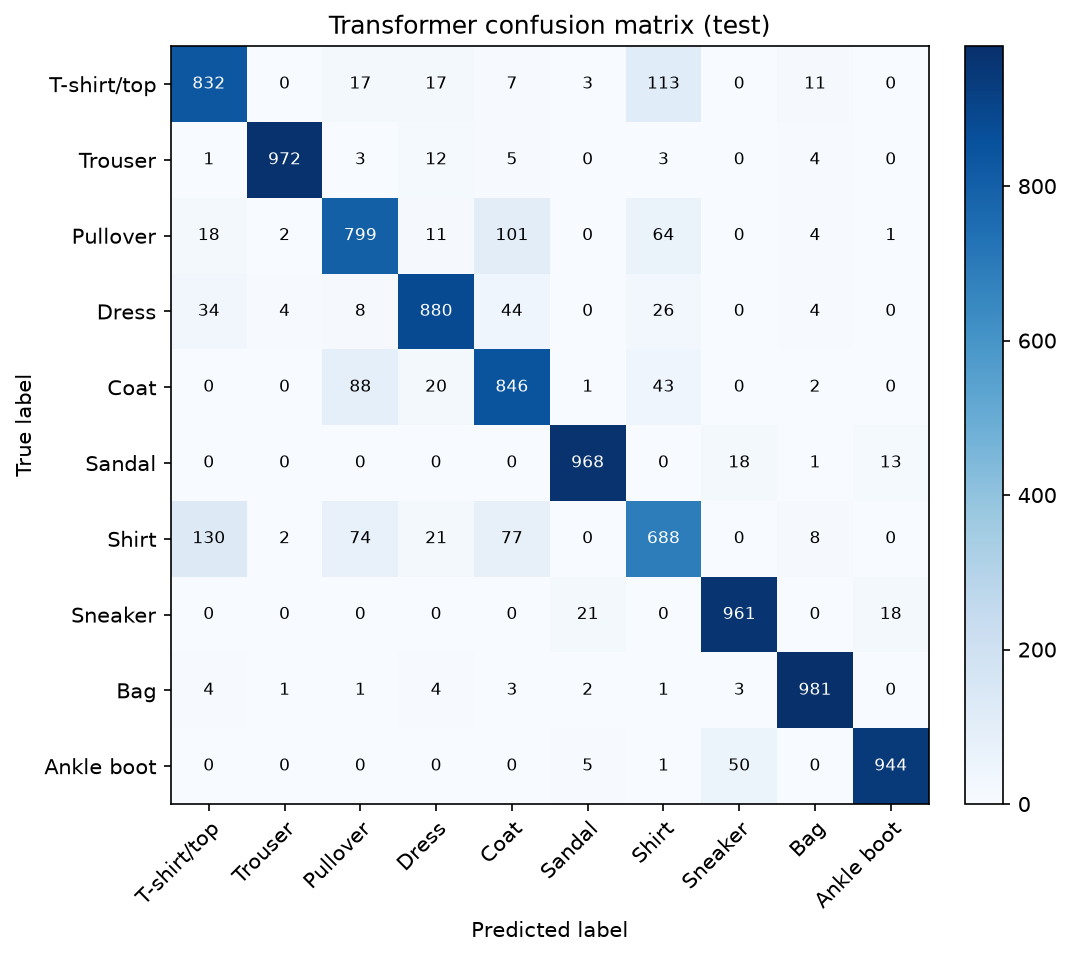

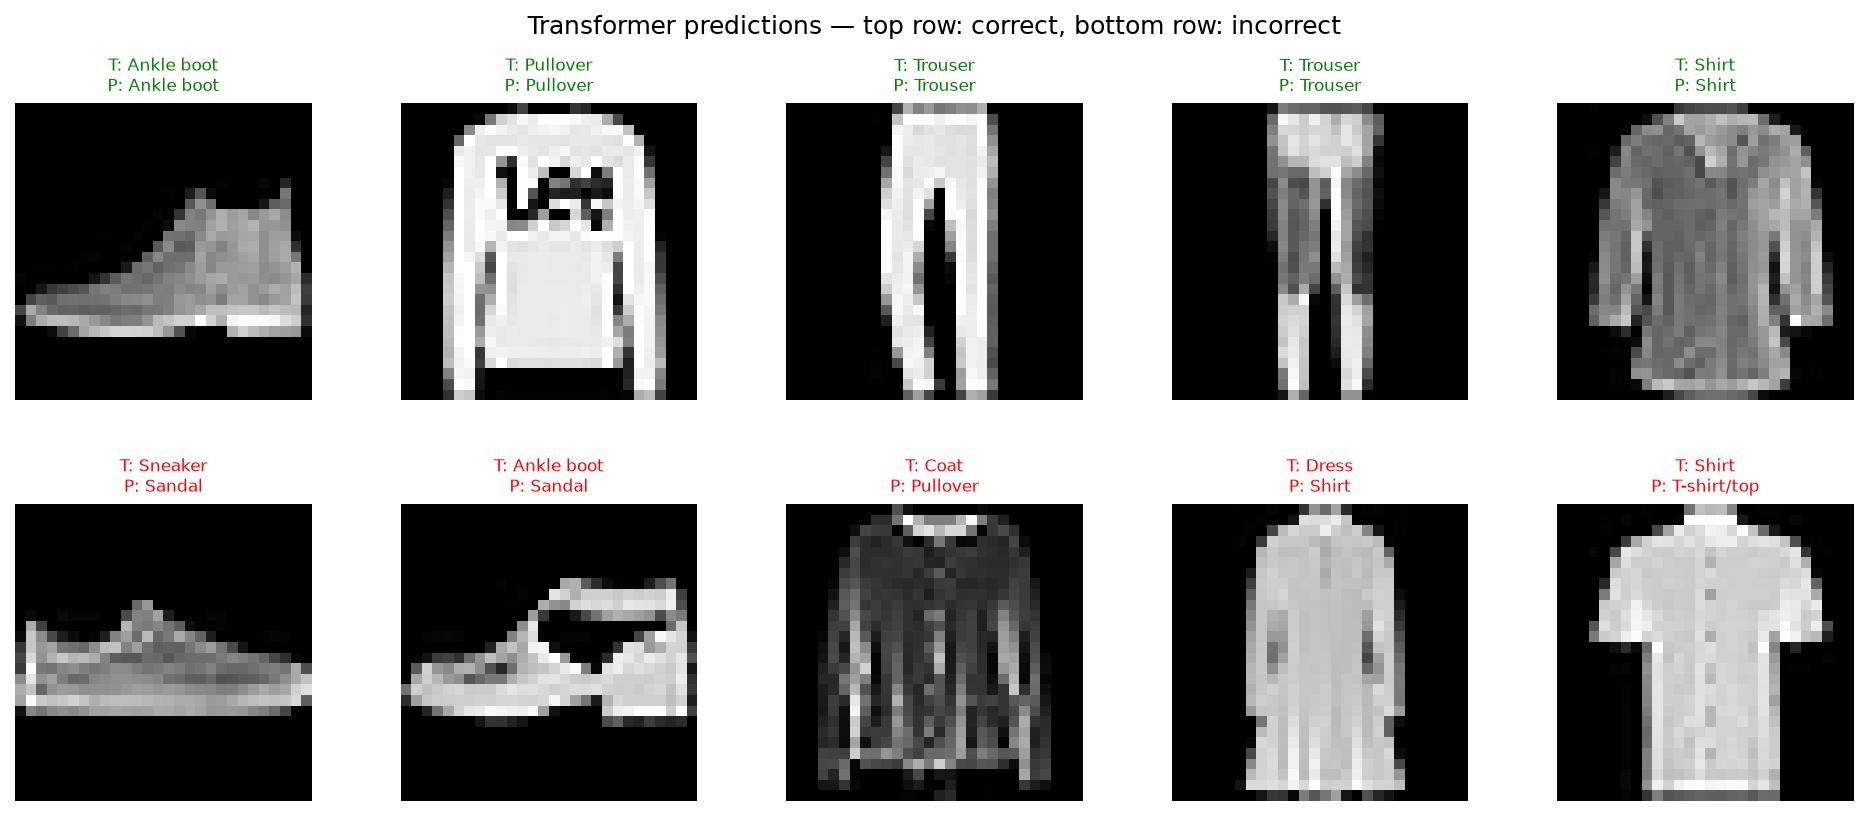

In [6]:
from IPython.display import Image, display

for display_name in ["CNN", "Transformer"]:
    print(f"### {display_name}")
    display(Image(filename=str(RESULTS_DIR / "curves" / f"{display_name.lower()}.png")))
    display(Image(filename=str(RESULTS_DIR / "confusion" / f"{display_name.lower()}.png")))
    display(Image(filename=str(RESULTS_DIR / "examples" / f"{display_name.lower()}.png")))
